# Fisher y predicted bias: gaussian_with_outlier

Modelo independiente basado en `Gaussian_with_outliers.py`:

$$g_j(z)\propto\int n_j(t)\,\mathcal N(z-t;\Delta z_j,s_j^2)\,dt,$$
$$n_i^{\rm model}(z)=\left(1-\sum_{j\ne i}c_{ij}\right)g_i(z)
   +\sum_{j\ne i}c_{ij}g_j(z).$$

Cada $g_j$ se normaliza en el intervalo de la malla. `c[i,j]` es la
fracción del **bin de salida i** aportada por la plantilla j.
Su diagonal es cero y cada fila debe sumar menos de uno para variar la mezcla.
Las densidades `neff` se mantienen como entradas independientes del sondeo.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import tables_io
import fisherA2Z.fisher_flex as ff
from fisherA2Z import nz_gaussian_outlier_pro as nzg

FisherFlex = ff.FisherFlex
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

## Datos y configuración

Se usa `source_year1_outliers_OFF.npz`. La media del ensemble sirve como plantilla;
`samples` calibra automáticamente los desplazamientos y anchos de convolución.
La mezcla `c_fid` queda fija. `nz_truth` se reserva para el cálculo del bias.

Con esta modalidad, los fiduciales finales son **la media de los parámetros
ajustados a las realizaciones**, no los valores iniciales `DZ_FID` y `STD_B_FID`,
ni necesariamente el ajuste a la PDF media. Se mantiene el modelo de convolución.


In [2]:
REPO = Path(ff.__file__).resolve().parents[2]
EXAMPLE_DIR = REPO / "examples" / "nzdc_example"
DATA_FILE = REPO.parent / "yaw_bins" / "Results" / "source_year1_outliers_OFF.npz"
BHAT_FILE = EXAMPLE_DIR / "nz_challenge_taskset_1_cardinal_1yr_bhat_wfd.hdf5"
OUTPUT_DIR = EXAMPLE_DIR / "outputs_gaussian_outlier_pro"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DZ_FID = 0.001       # Escalar o un valor por plantilla; positivo desplaza hacia mayor z.
STD_B_FID = 1.0      # Desviación estándar de la convolución, en redshift.
OUTLIER_FRACTION = 0.01
VARY_MIXING = False  # La calibración automática mantiene fija la mezcla.
SUBDIVISIONS = 32
FORECAST_PARAMS = dict(ell_min_cs=300, ell_max_cs=1800)
FISHER_FILE = OUTPUT_DIR / f"fisher_{DATA_FILE.stem}_gaussian_outlier_pro.npz"

with np.load(DATA_FILE) as data:
    z_native = np.asarray(data["z_grid"], dtype=float)
    samples = np.asarray(data["samples"], dtype=float)
    nz_true_native = nzg.normalize_nz(z_native, data["nz_truth"])
n_bins, n_realizations, n_z = samples.shape
nz_central_native = nzg.normalize_nz(z_native, samples.mean(axis=1))
if nz_true_native.shape != nz_central_native.shape:
    raise ValueError("Central y truth deben tener los mismos bins y malla.")

c_fid = np.zeros((n_bins, n_bins))
if n_bins > 1:
    c_fid[:] = OUTLIER_FRACTION / (n_bins - 1)
    np.fill_diagonal(c_fid, 0)
gaussian_config = dict(
    dz=DZ_FID, std_b=STD_B_FID, c=c_fid, vary_mixing=VARY_MIXING,
    calibration_n_jobs=4,
    calibration_max_realizations=None,  # None: todas; un entero limita explícitamente el ajuste.
)
print("Datos:", DATA_FILE.name, "| realizaciones por bin:", n_realizations)
print("Fracción outlier por bin:", nzg.outlier_fraction(c_fid))
print("Orden de parámetros/prior del primer bin:", nzg.parameter_names(0, n_bins, VARY_MIXING))

Datos: source_year1_outliers_OFF.npz | realizaciones por bin: 199499
Fracción outlier por bin: [0.01 0.01 0.01 0.01 0.01]
Orden de parámetros/prior del primer bin: ['gdz1', 'gsigma1']


## Densidad efectiva

In [3]:
N_CATALOG = 3_505_864
N_SAMPLED = 1_000_000
AREA_ARCMIN2 = 107.4295 * 3600
bhat_table = tables_io.read(str(BHAT_FILE))
counts = np.bincount(bhat_table["bhat_for_wide_data"], minlength=n_bins)[:n_bins]
neff = counts * (N_CATALOG / AREA_ARCMIN2) / N_SAMPLED
print("Conteos por bin:", counts)
print("neff [gal/arcmin²]:", neff)

Conteos por bin: [196661 196375 189284 214686 202994]
neff [gal/arcmin²]: [1.7827369  1.7801443  1.71586421 1.94613397 1.8401457 ]


## Reconstrucción y Fisher

Las PDFs centrales se representan en la malla fina de Fisher. Las realizaciones
se conservan en su malla nativa, indicada por `z_realizations=z_native`.
El ajuste interpola una realización cada vez; no crea un ensemble de 10 GB.

`nz_source` contiene las plantillas antes de convolución. `flex.nz_source_fid`
es el resultado de convolucionarlas y mezclarlas con los parámetros calibrados.
La calibración trabaja con `VARY_MIXING=False`.


z_grid = np.unique(np.concatenate([
    np.linspace(a, b, SUBDIVISIONS + 1)
    for a, b in zip(z_native[:-1], z_native[1:])
]))
nz_central = np.array([np.interp(z_grid, z_native, row) for row in nz_central_native])
nz_true = np.array([np.interp(z_grid, z_native, row) for row in nz_true_native])
flex = FisherFlex(
    nz_source=nz_central,
    z_grid=z_grid,
    nz_realizations=None,
    photoz_prior_cov=PHOTOZ_PRIOR_COV,
    neff_source=neff, fsky=0.5, sigma_e=0.26,
    mode="cosmic_shear",
    nz_model="gaussian_outlier_pro",
    gaussian_outlier_pro_kwargs=gaussian_config,
    prior_mode="full", deriv_method="central",
)
nz_reconstructed = flex.nz_source_fid
print("Malla:", z_grid.size, "nodos")
print("Parámetros foto-z libres:", n_bins * flex.n_pz_per_bin)
print("Normalizaciones:", np.trapz(nz_reconstructed, z_grid, axis=1))

In [ ]:
gaussian_config["calibration_max_realizations"] = 500

In [4]:
z_grid = np.unique(np.concatenate([
    np.linspace(a, b, SUBDIVISIONS + 1)
    for a, b in zip(z_native[:-1], z_native[1:])
]))
nz_central = np.array([np.interp(z_grid, z_native, row) for row in nz_central_native])
nz_true = np.array([np.interp(z_grid, z_native, row) for row in nz_true_native])
flex = FisherFlex(
    nz_source=nz_central,
    z_grid=z_grid,
    nz_realizations=samples,
    z_realizations=z_native,  # Malla original de los samples
    realizations_axis=1,
    neff_source=neff,
    fsky=0.5,
    sigma_e=0.26,
    mode="cosmic_shear",
    nz_model="gaussian_outlier_pro",
    gaussian_outlier_pro_kwargs=gaussian_config,
    prior_mode="full",
    deriv_method="central",
)
nz_reconstructed = flex.nz_source_fid
print("Malla:", z_grid.size, "nodos")
print("Parámetros foto-z libres:", n_bins * flex.n_pz_per_bin)
print("Normalizaciones:", np.trapz(nz_reconstructed, z_grid, axis=1))
print("Fiduciales dz:", flex.gpro_dz)
print("Fiduciales std_b:", flex.gpro_std_b)
print("Forma del prior calculado:", flex.pz_prior_cov.shape)
print("Fracciones de ajustes en el ancho mínimo:", flex.gpro_calibration["boundary_fraction"])
print("Realizaciones usadas:", flex.gpro_calibration["n_realizations"])

Fitting Gaussian convolution parameters: 199499/199499 realizations x 5 bins, 4 processes ...
Gaussian calibration: 0% (128/997495 fits)
Gaussian calibration: 5% (49920/997495 fits)
Gaussian calibration: 10% (99840/997495 fits)
Gaussian calibration: 15% (149632/997495 fits)
Gaussian calibration: 20% (199552/997495 fits)
Gaussian calibration: 25% (249472/997495 fits)
Gaussian calibration: 30% (299264/997495 fits)
Gaussian calibration: 35% (349184/997495 fits)
Gaussian calibration: 40% (399104/997495 fits)
Gaussian calibration: 45% (448896/997495 fits)
Gaussian calibration: 50% (498816/997495 fits)
Gaussian calibration: 55% (548736/997495 fits)
Gaussian calibration: 60% (598528/997495 fits)
Gaussian calibration: 65% (648448/997495 fits)
Gaussian calibration: 70% (698368/997495 fits)
Gaussian calibration: 75% (748160/997495 fits)
Gaussian calibration: 80% (798080/997495 fits)
Gaussian calibration: 85% (847872/997495 fits)
Gaussian calibration: 90% (897792/997495 fits)
Gaussian calibration

/home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/fisher_flex.py:1458: UserWarning: Gaussian calibration: fractions of fits at minimum width = [0.628, 0.944, 0.851, 0.705, 0.465]. The empirical prior is a Gaussian approximation to boundary-limited fits, not evidence of an interior width measurement. Inspect gpro_calibration.
  warnings.warn("Gaussian calibration: fractions of fits at minimum width = "


Malla: 1249 nodos
Parámetros foto-z libres: 10
Normalizaciones: [1. 1. 1. 1. 1.]
Fiduciales dz: [-1.55132708e-04  7.91375356e-05  1.94588094e-04  3.05841509e-04
  2.85174085e-04]
Fiduciales std_b: [0.006964   0.00488975 0.00501107 0.00615161 0.00920812]
Forma del prior calculado: (5, 2, 2)
Fracciones de ajustes en el ancho mínimo: [0.6278026456272964, 0.9444107489260598, 0.8506909809071724, 0.7048556634369094, 0.4650599752379711]
Realizaciones usadas: 199499


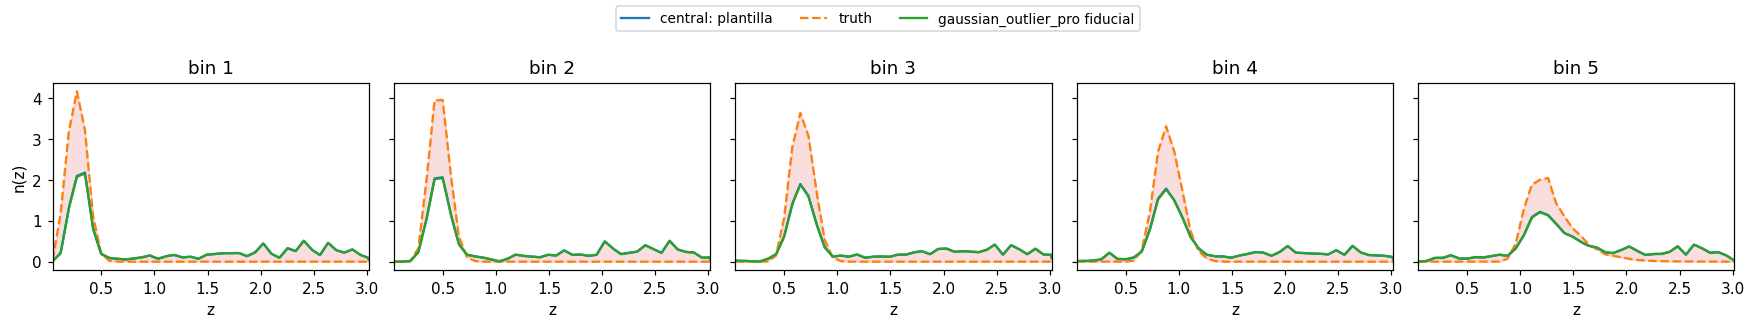

In [5]:
fig, axes = plt.subplots(1, n_bins, figsize=(16, 3), sharey=True, squeeze=False)
for b, ax in enumerate(axes[0]):
    ax.plot(z_grid, nz_central[b], color="C0", label="central: plantilla" if b == 0 else None)
    ax.plot(z_grid, nz_true[b], "--", color="C1", label="truth" if b == 0 else None)
    ax.plot(z_grid, nz_reconstructed[b], color="C2", label="gaussian_outlier_pro fiducial" if b == 0 else None)
    ax.fill_between(z_grid, nz_reconstructed[b], nz_true[b], color="C3", alpha=0.15)
    ax.set(title=f"bin {b+1}", xlabel="z", xlim=(z_grid[0], z_grid[-1]))
axes[0, 0].set_ylabel("n(z)")
fig.legend(loc="upper center", ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(OUTPUT_DIR / "nz_gaussian_outlier_pro.png", dpi=160, bbox_inches="tight")
plt.show()

## Forecast

Primero se calculan los espectros, sus derivadas y la covarianza con
`compute()`. Después `forecast()` aplica los cortes y marginaliza los
parámetros libres. No se cargan derivadas de otro modelo.

In [6]:
flex.compute(parallel=True, n_proc=2, save=str(FISHER_FILE))
res = flex.forecast(**FORECAST_PARAMS)
# Detecta una matriz sin covarianza positiva; no añade priors artificiales.
np.linalg.cholesky((res.cov + res.cov.T) / 2)
s8, s8_err = res.s8()
print(f"Cosmic shear, gaussian_outlier_pro: S_8 = {s8:.4f} +/- {s8_err:.4f}")
print(f"FoM(w0,wa) = {res.fom('w_0', 'w_a'):.2f}")
print("Resultados:", FISHER_FILE)

Computing the fiducial data vector and covariance ...
Computing derivatives for 31 parameters (parallel) ...
Done.
Saved to /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_gaussian_outlier_pro/fisher_source_year1_outliers_OFF_gaussian_outlier_pro.npz
Cosmic shear, gaussian_outlier_pro: S_8 = 0.8523 +/- 0.0132
FoM(w0,wa) = 5.48
Resultados: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/examples/nzdc_example/outputs_gaussian_outlier_pro/fisher_source_year1_outliers_OFF_gaussian_outlier_pro.npz


## Predicted bias

Se compara `nz_truth` con la PDF convolucionada y mezclada con los fiduciales
obtenidos de `samples`:
$\Delta\theta=F^{-1}J^T\,\mathrm{Cov}^{-1}(C^{\rm truth}-C^{\rm fid})$.
El prior empleado procede de la dispersión de los parámetros ajustados.

Las flechas son una predicción local de primer orden. Un residuo de espectros
grande, muchos ajustes en el límite de anchura o un desplazamiento fuera del
dominio físico limitan su interpretación cuantitativa. Se conservan todas
las tablas de bias y las gráficas corner + arrows y contour + arrow.

In [7]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=FORECAST_PARAMS)
COSMO_PARAMS = ["omega_m", "sigma_8", "w_0", "w_a"]
print(bias.summary(COSMO_PARAMS))
if bias.shifted_fid("omega_m") > 0 and bias.shifted_fid("sigma_8") > 0:
    s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
    print(f"\nS_8: {s8_fid:.4f} -> {s8_shifted:.4f} ({ds8:+.4f}, {ds8_sigma:+.2f} sigma)")
else:
    print("\nNo se calcula S_8 desplazado: el bias lineal sale del dominio físico.")
    print("Las flechas son un diagnóstico; calibra dz, std_b y c antes de interpretar el bias.")
print(f"Residuo fraccional medio de los espectros (MAFE): {bias.mafe():.2%}")

parameter         fiducial        bias  bias/sigma     shifted
omega_m             0.3156    -0.19243      -7.224     0.12317
sigma_8              0.831     0.11756       3.745     0.94856
w_0                     -1    -0.30929      -1.048     -1.3093
w_a                      0     -2.9403      -3.072     -2.9403

S_8: 0.8523 -> 0.6078 (-0.2445, -18.48 sigma)
Residuo fraccional medio de los espectros (MAFE): 54.15%


## Bias en dos dimensiones

`bias/sigma` es una comparación marginal por parámetro. `bias_2d`
utiliza la covarianza conjunta del par, marginalizando los demás.

In [8]:
PARAMETER_PAIRS = [("omega_m", "sigma_8"), ("w_0", "w_a")]
for pair in PARAMETER_PAIRS:
    print(bias.bias_2d(*pair))
    print()

bias in the (omega_m, sigma_8) plane
  omega_m           0.3156 ->     0.12317   (-7.22 sigma_1D)
  sigma_8            0.831 ->     0.94856   (+3.75 sigma_1D)
  joint: chi2 = 118.316, sqrt(chi2) = 10.88, enclosing 100.0% of the posterior
  direction: +148.6 deg;  inside 1 sigma: False;  inside 2 sigma: False

bias in the (w_0, w_a) plane
  w_0                   -1 ->     -1.3093   (-1.05 sigma_1D)
  w_a                    0 ->     -2.9403   (-3.07 sigma_1D)
  joint: chi2 = 36.941, sqrt(chi2) = 6.08, enclosing 100.0% of the posterior
  direction: -96.0 deg;  inside 1 sigma: False;  inside 2 sigma: False



## Corner + arrows

Azul: forecast fiducial. Naranja: desplazamiento predicho y contorno
trasladado. El contorno naranja conserva la covarianza fiducial;
no es un nuevo ajuste calculado en el punto desplazado.

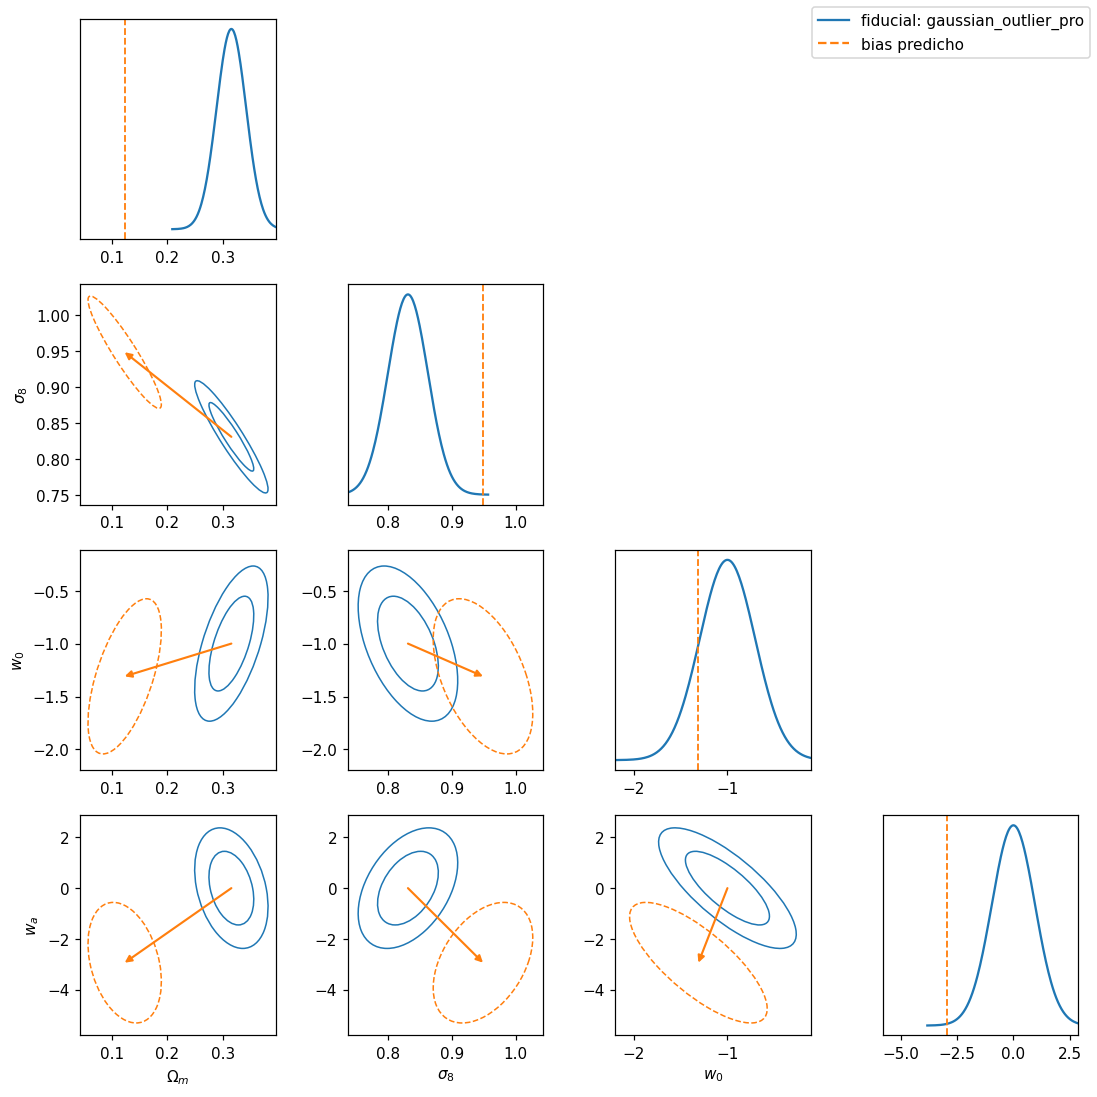

In [9]:
# Incluye ambos centros y sus contornos para no recortar las elipses desplazadas.
def limits_with_bias(parameter):
    centers = (res.param_fid[parameter], bias.shifted_fid(parameter))
    margin = 3.0 * res.sigma(parameter)
    return min(centers) - margin, max(centers) + margin

legend_handles = [
    Line2D([], [], color="C0", label="fiducial: gaussian_outlier_pro"),
    Line2D([], [], color="C1", ls="--", label="bias predicho"),
]
fig = res.corner(COSMO_PARAMS, color="C0", label="gaussian_outlier_pro", figsize=(10, 10))
bias.corner_arrows(COSMO_PARAMS, fig=fig, shifted_contour=True, color="C1")
axes = np.asarray(fig.axes).reshape(len(COSMO_PARAMS), len(COSMO_PARAMS))
for row, p_y in enumerate(COSMO_PARAMS):
    for col, p_x in enumerate(COSMO_PARAMS[:row + 1]):
        axes[row, col].set_xlim(limits_with_bias(p_x))
        if row != col:
            axes[row, col].set_ylim(limits_with_bias(p_y))
fig.legend(handles=legend_handles, loc="upper right", fontsize=10)
fig.savefig(OUTPUT_DIR / "corner_gaussian_outlier_pro_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## Contornos y flechas en los dos planos cosmológicos

Los contornos azules corresponden a las regiones conjuntas de 68.3% y
95.4%. Las flechas muestran el bias; el contorno naranja discontinuo
representa la región de 95.4% trasladada.

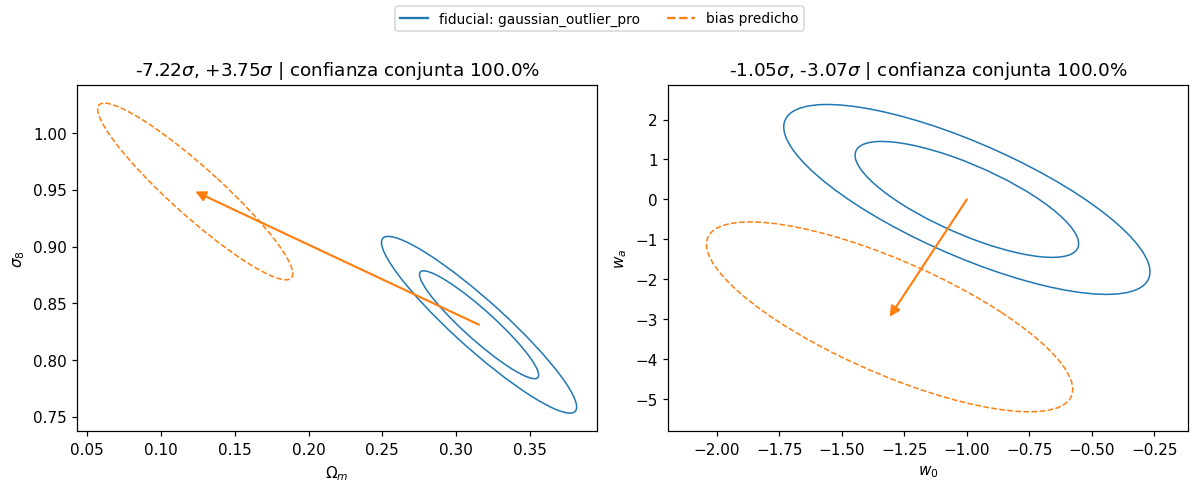

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (p1, p2) in zip(axes, PARAMETER_PAIRS):
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    joint = bias.bias_2d(p1, p2)
    ax.set_xlim(limits_with_bias(p1))
    ax.set_ylim(limits_with_bias(p2))
    ax.set_title(
        rf"{bias.n_sigma(p1):+.2f}$\sigma$, {bias.n_sigma(p2):+.2f}$\sigma$"
        f" | confianza conjunta {joint.confidence:.1%}"
    )
fig.legend(handles=legend_handles, loc="upper center", ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUTPUT_DIR / "contours_gaussian_outlier_pro_bias.png", dpi=160, bbox_inches="tight")
plt.show()